# Solar filament instance segmentation: selection on a component tree

This notebook walks through the complete pipeline that produced the submission file, from the input images to the CSV and
the evaluation on out-of-fold predictions for the 707 training images.

> **What this notebook does by default** (all switches `False`)
> 1. loads the stored result of every expensive stage from `artifacts/` (they are part of the repository, nothing is downloaded);
> 2. rebuilds the selection with the stored LightGBM models and writes `outputs/submission.csv`;
> 3. checks that this file is identical to `reference/submission.csv` (the submitted file);
> 4. evaluates the out-of-fold selection (Panoptic Quality, Dice and IoU distributions, one-to-many and many-to-one relations).
>
> It needs no GPU. Pictures and the exact evaluation appear when the competition folder and the training annotation file are
> available (environment variables `PQTREE_COMPETITION_DIR`, `PQTREE_TRAIN_JSON`; see `README.md`); without them the cells
> that need them are skipped. Every expensive stage can be recomputed with a switch in the "Advanced" block below.

**Idea in one paragraph.** A dense network ensemble gives, for every pixel, the probability of belonging to a filament.
Thresholding this map at eight levels (0.2 ... 0.9) and taking connected components gives many overlapping *candidate*
masks that form a tree: a component at one threshold lies inside one component of the next lower threshold. A model
predicts for each candidate its expected matched IoU with the annotators. Because the competition metric is a pooled
Panoptic Quality (PQ), the best set of non-overlapping candidates of an image is found exactly by a small dynamic
programme: keep a candidate if its predicted IoU exceeds a threshold `tau` (here 0.30), choosing between a mask and its
sub-masks wherever that gives the larger total.

**Stages**

| # | stage | hardware | switch (default `False` = load the stored result) |
|---|---|---|---|
| 0 | preprocessing (solar-disk standardisation, inside stages 1-3) | - | - |
| 1 | dense probability maps, uncertainty and family-gap maps | GPU | `RECOMPUTE_MAPS` |
| 2 | candidate component tree and features | CPU | `RECOMPUTE_CANDIDATES` |
| 3 | CNN candidate scorer (ResNet18 on crops, 5-fold cross-fitted) | GPU | `RETRAIN_CNN_SCORER` |
| 4a | instance detections of the detector fold models | GPU | `RECOMPUTE_DETECTIONS` |
| 4b | per-candidate detector evidence features | CPU, about 55 min | `RECOMPUTE_EVIDENCE` |
| 5 | hurdle LightGBM (hit probability x matched IoU) | CPU | `REFIT_LGBM` |
| 6 | selection (dynamic programme), RLE, CSV, validation | CPU | - |
| 7 | evaluation on the out-of-fold training predictions | CPU | - |

Stages 1, 3 (training) and 4a were produced on Kaggle T4 GPUs with the scripts that this package reorganises. Their results
are stored because GPU inference is not bit-reproducible; `tools/gpu_stage_check.py` compares the packaged stages with the
stored results.

## Setup and switches

In [1]:
import os, sys, json, time, hashlib, resource
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "pqtree").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from pqtree import config, candidates, dense_maps, cnn_scorer, detector_evidence, lgbm_scorer, selection, evaluation, visualize
from pqtree.artifacts import fetch_artifact, load_table

# ---- Advanced: recompute a stage instead of loading its stored result (default False) -----------------------------
RECOMPUTE_MAPS = False            # stage 1, needs a GPU, the U-Net weights and the competition images
RECOMPUTE_CANDIDATES = False      # stage 2, needs the competition images (and TRAIN_JSON for the training targets)
RETRAIN_CNN_SCORER = False        # stage 3, needs a GPU, timm and the competition images
APPLY_STORED_CNN_WEIGHTS = False  # stage 3, run the stored CNN fold weights on the test crops (needs torch, timm, test images)
RECOMPUTE_DETECTIONS = False      # stage 4a, needs a GPU, ultralytics and the detector weights
RECOMPUTE_EVIDENCE = False        # stage 4b, CPU only, about 55 minutes
REFIT_LGBM = False                # stage 5, CPU only, about 15 minutes

# ---- paths (override with environment variables) ---------------------------------------------------------------------
COMPETITION_DIR = Path(os.environ.get("PQTREE_COMPETITION_DIR", ROOT / "data" / "MAGFiLO_1.0_Kaggle_2026"))
TRAIN_JSON = Path(os.environ.get("PQTREE_TRAIN_JSON", ROOT / "data" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"))
UNET_WEIGHTS = Path(os.environ.get("PQTREE_UNET_WEIGHTS", ROOT / "third_party_weights" / "solar-filament-unet-weights"))
DETECTOR_WEIGHTS = Path(os.environ.get("PQTREE_DETECTOR_WEIGHTS", ROOT / "third_party_weights" / "solar-filament-weights"))
OUT_DIR = Path(os.environ.get("PQTREE_OUT", ROOT / "outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_IMAGES = COMPETITION_DIR / "train" / "train_images"
TEST_IMAGES = COMPETITION_DIR / "test" / "test_images"
REFERENCE = ROOT / "reference" / "submission.csv"
HAVE_TEST_IMAGES = TEST_IMAGES.exists()
HAVE_ANNOTATIONS = TRAIN_JSON.exists() and TRAIN_IMAGES.exists()

def image_reader(folder):
    """stem -> grey-scale uint8 image"""
    return lambda stem: cv2.imread(str(Path(folder) / f"{stem}.jpeg"), cv2.IMREAD_GRAYSCALE)

# ---- guard against combinations of switches that would silently mix old and new stage outputs ------------------------
problems = []
if RECOMPUTE_MAPS and not all([RECOMPUTE_CANDIDATES, RETRAIN_CNN_SCORER, RECOMPUTE_DETECTIONS, RECOMPUTE_EVIDENCE, REFIT_LGBM]):
    problems.append("RECOMPUTE_MAPS needs RECOMPUTE_CANDIDATES, RETRAIN_CNN_SCORER, RECOMPUTE_DETECTIONS, RECOMPUTE_EVIDENCE and "
                    "REFIT_LGBM as well (all later stages depend on the maps; candidate ids change with them)")
if RECOMPUTE_DETECTIONS and not RECOMPUTE_EVIDENCE:
    problems.append("RECOMPUTE_DETECTIONS needs RECOMPUTE_EVIDENCE (new detections only matter through the evidence features)")
if problems:
    raise RuntimeError("Inconsistent switches:\n  - " + "\n  - ".join(problems))

T_START = time.time()
print("recompute switches:", dict(maps=RECOMPUTE_MAPS, candidates=RECOMPUTE_CANDIDATES, cnn=RETRAIN_CNN_SCORER,
                                    detections=RECOMPUTE_DETECTIONS, evidence=RECOMPUTE_EVIDENCE, lgbm=REFIT_LGBM))
print("competition images for the pictures:", HAVE_TEST_IMAGES, "| annotations for the evaluation:", HAVE_ANNOTATIONS)

recompute switches: {'maps': False, 'candidates': False, 'cnn': False, 'detections': False, 'evidence': False, 'lgbm': False}
competition images for the pictures: True | annotations for the evaluation: True


## Stage 0 and 1: preprocessing and dense probability maps

*Preprocessing.* All networks work on the raw 2048 x 2048 grey-scale H-alpha images. The grey values are standardised
over the solar disk (a mean and a standard deviation computed from the pixels inside a disk of radius 950 px around the
image centre; for the hand-crafted features: from the pixels brighter than 15). The dense networks see the full image,
without cropping or resizing.

*Dense maps.* The public ensemble `dariushafshar/solar-filament-unet-weights` has five folds of two U-Nets (ResNet34 and
EfficientNetV2-S encoders), trained on the 707 training images only. Every model predicts eight dihedral views of the
image (four rotations, with and without a flip); the predictions are rotated back and averaged.

* training images: the *out-of-fold* map, i.e. the mean of the two models of the fold that did not see the image;
* test images: the mean of all ten models;
* two further maps per image: the standard deviation over the eight views ("view uncertainty") and the absolute
  difference of the two architectures ("family gap").

All maps are stored as 8-bit images (probability x 255). File names ending in `_unet` belong to this stage.

oof_probs_unet     707 images
oof_unc_unet       707 images
oof_fam_unet       707 images
test_probs_unet    180 images
test_unc_unet      180 images
test_fam_unet      180 images


example test image: 20110531070514Th | crop (y0, y1, x0, x1): (1451, 1963, 920, 1432)


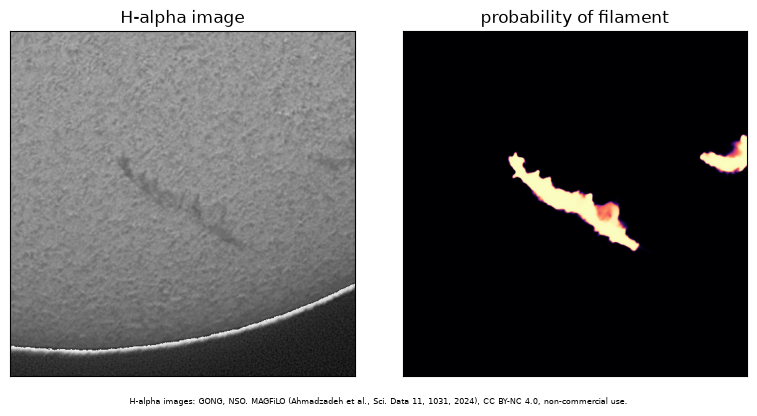

In [2]:
MAP_NAMES = [f"{split}_{kind}_unet" for split in ("oof", "test") for kind in ("probs", "unc", "fam")]
if RECOMPUTE_MAPS:
    paths = dense_maps.compute_dense_maps(UNET_WEIGHTS, TRAIN_IMAGES, TEST_IMAGES, OUT_DIR / "maps")
    maps = {n: np.load(paths[n]) for n in MAP_NAMES}
else:
    maps = {n: np.load(fetch_artifact(n + ".npz")) for n in MAP_NAMES}
for n in MAP_NAMES:
    print(f"{n:17s} {len(maps[n].files):4d} images")

# example test image for the pictures: the one at the 75th percentile of the area with probability >= 0.5
test_stems = sorted(maps["test_probs_unet"].files)
mass = pd.Series({s: int((maps["test_probs_unet"][s] >= 128).sum()) for s in test_stems}).sort_values()
EX_STEM = mass.index[int(0.75 * len(mass))]
ex_prob = maps["test_probs_unet"][EX_STEM]
n_cc, lab_cc, st_cc, _ = cv2.connectedComponentsWithStats((ex_prob >= 128).astype(np.uint8), connectivity=8)
EX_BOX = visualize.box_around(lab_cc == 1 + int(np.argmax(st_cc[1:, cv2.CC_STAT_AREA])), size=512)
ex_img = image_reader(TEST_IMAGES)(EX_STEM) if HAVE_TEST_IMAGES else None
print("example test image:", EX_STEM, "| crop (y0, y1, x0, x1):", EX_BOX)
fig = visualize.dense_map_figure(ex_prob, EX_BOX, ex_img); plt.show()

## Stage 2: candidate masks as a component tree

Each probability map is thresholded at 0.2, 0.3, ..., 0.9. The 8-connected components (at least 30 pixels) of every
binary map are the candidates. A component at a higher threshold lies inside exactly one component of the next lower
threshold (its *parent*), so the candidates of an image form a forest.

Each candidate gets 33 descriptors: probability statistics under the mask (mean, maximum, standard deviation, blurred
versions), darkness relative to the local background at three scales, shape (area, bounding box, fill, elongation, axis
lengths), position on the disk (distance from the centre, limb distance), tree context (area ratio to the parent, number
of children, number of candidates at the 0.5 level in the image), crowding (distance to the nearest candidate,
neighbours within 150 and 200 px, area rank among them), the observing station encoded from the file name, and the mean
and maximum of the uncertainty and family-gap maps under the mask.

For the training images each candidate also receives its target, computed from the annotation file: for every annotator
the IoU with the best of that annotator's polygons if it exceeds 0.5 (else 0). The target `u` is the mean over the
annotators, `h` the share of annotators with a match and `m` the mean IoU over those that matched; `u = h x m`.
Only these aggregated columns and the number of annotated masks per image are stored (`artifacts/candidates_oof.tbl.npz`,
`artifacts/ngt_train.json`); no polygon, mask or annotator identifier is stored.

training candidates: (60116, 46) images with candidates: 703
test candidates    : (15520, 46) images: 180
ground-truth masks in the 707 training images (all annotators): 8199
candidates per level (test): {0: 2217, 1: 2128, 2: 2059, 3: 1962, 4: 1917, 5: 1833, 6: 1744, 7: 1660}


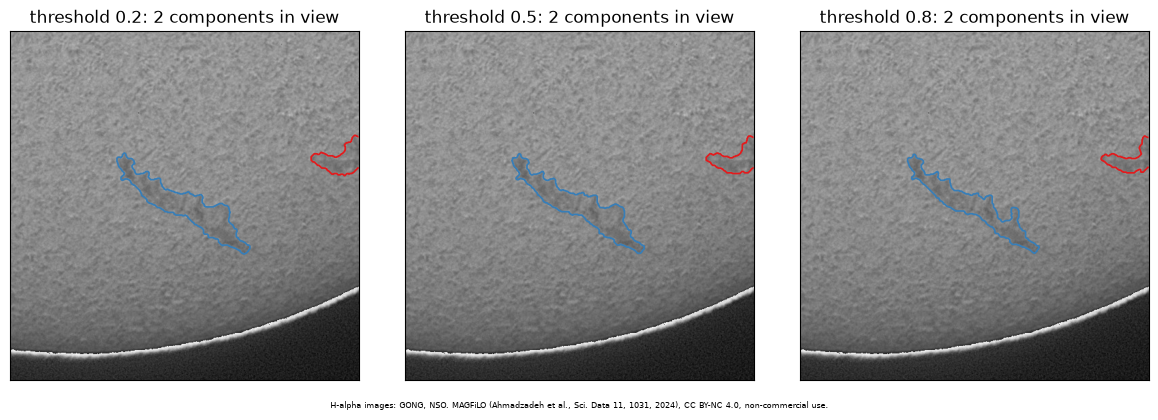

In [3]:
if RECOMPUTE_CANDIDATES:
    extra = lambda split: {"unc": maps[f"{split}_unc_unet"], "fam": maps[f"{split}_fam_unet"]}
    annotations = candidates.load_annotations(TRAIN_JSON)
    cands_oof, ngt = candidates.build_candidates(maps["oof_probs_unet"], image_reader(TRAIN_IMAGES), extra("oof"), annotations=annotations)
    with selection.LabelWriter(OUT_DIR / "test_components.npz") as writer:
        cands_test, _ = candidates.build_candidates(maps["test_probs_unet"], image_reader(TEST_IMAGES), extra("test"), label_sink=writer.add)
    test_label_path = OUT_DIR / "test_components.npz"
else:
    cands_oof = load_table(fetch_artifact("candidates_oof.tbl.npz"))
    cands_test = load_table(fetch_artifact("candidates_test.tbl.npz"))
    ngt = json.load(open(fetch_artifact("ngt_train.json")))
    test_label_path = fetch_artifact("test_components.npz")
N_GT = sum(ngt.values())
print("training candidates:", cands_oof.shape, "images with candidates:", cands_oof.stem.nunique())
print("test candidates    :", cands_test.shape, "images:", cands_test.stem.nunique())
print("ground-truth masks in the 707 training images (all annotators):", N_GT)
print("candidates per level (test):", cands_test.groupby("level").size().to_dict())
test_components = selection.stored_label_images(test_label_path)
ex_labels = [test_components(EX_STEM)(lv) for lv in range(8)]
fig = visualize.candidate_levels_figure(ex_prob, ex_labels, (0, 3, 6), [config.LEVELS[i] for i in (0, 3, 6)], EX_BOX, ex_img); plt.show()

## Stage 3: CNN candidate scorer

A ResNet18 (timm, four input channels) looks at a square crop around each candidate (side 1.6 x the larger side of the
bounding box, resized to 128 px). Channels: the standardised image, the probability map, the candidate mask, and the
mask `prob >= 0.2`. Three scalars (log crop side, threshold of the level, log area) are appended to the pooled features.
The network predicts `u` with a binary cross-entropy loss on the soft target. Training: 5 folds split by image, 8 epochs,
AdamW with a one-cycle schedule, rotations and flips as augmentation, four-view test-time averaging. The prediction for a
training candidate comes from the fold model that did not see its image; the test prediction is the mean of the five
fold models. The prediction is one of the inputs of the LightGBM stage (feature `cnn_u`).

`APPLY_STORED_CNN_WEIGHTS = True` runs the five stored fold models on the test crops (needs torch, timm and the test images)
and prints the difference to the stored scores.

In [4]:
KEY = config.KEY
if RETRAIN_CNN_SCORER:
    crops_tr, sc_tr = cnn_scorer.extract_crops(cands_oof, maps["oof_probs_unet"], image_reader(TRAIN_IMAGES))
    crops_te, sc_te = cnn_scorer.extract_crops(cands_test, maps["test_probs_unet"], image_reader(TEST_IMAGES))
    oof_u, test_u = cnn_scorer.train_cross_fit(cands_oof, crops_tr, sc_tr, crops_te, sc_te, weights_dir=OUT_DIR / "cnn_weights")
    cnn_oof = cands_oof[KEY].reset_index(drop=True).assign(cnn_u=oof_u)
    cnn_test = cands_test[KEY].reset_index(drop=True).assign(cnn_u=test_u)
else:
    cnn_oof = pd.read_csv(fetch_artifact("cnn_scores_oof.csv.gz"))
    cnn_test = pd.read_csv(fetch_artifact("cnn_scores_test.csv.gz"))
    if APPLY_STORED_CNN_WEIGHTS:
        crops_te, sc_te = cnn_scorer.extract_crops(cands_test, maps["test_probs_unet"], image_reader(TEST_IMAGES))
        weights = [fetch_artifact(f"cnn_scorer_f{k}.pt") for k in range(5)]
        again = cnn_scorer.predict_with_stored_weights(weights, crops_te, sc_te)
        print("max abs difference to the stored test scores:", float(np.abs(again - cnn_test.cnn_u.values).max()))
print("CNN scores: training", cnn_oof.shape, "test", cnn_test.shape)
tgt = cands_oof[KEY + ["u"]].merge(cnn_oof, on=KEY)
print("correlation of the out-of-fold CNN score with the target u:", round(float(np.corrcoef(tgt.u, tgt.cnn_u)[0, 1]), 4))
print(tgt.groupby(pd.qcut(tgt.cnn_u, 5, duplicates="drop"), observed=True).u.agg(["count", "mean"]).round(3).rename(columns={"mean": "mean target u"}))

CNN scores: training (60116, 4) test (15520, 4)
correlation of the out-of-fold CNN score with the target u: 0.6647
                            count  mean target u
cnn_u                                           
(-0.0009999999508, 0.0221]  12024          0.025
(0.0221, 0.18]              12023          0.168
(0.18, 0.422]               12023          0.323
(0.422, 0.617]              12023          0.486
(0.617, 0.861]              12023          0.631


## Stage 4: instance evidence from detector models

The public release `notoverkil/solar-filament-weights` contains 5-fold models of four instance detectors (YOLO11m-seg at 1536
and 2048 px, YOLO26m-seg at 1536 px, Mask R-CNN at 1536 px), all trained on the 707 training images with a published fold
assignment. Training images are processed only by the fold model that did not see them; test images by all five.

* **4a** (GPU): every detected instance with confidence >= 0.05 is stored as a run-length mask with its confidence.
* **4b** (CPU): for each candidate, each detector family and each fold model: the best IoU with any instance, that
  instance's confidence, the share of the candidate covered by instances with confidence >= 0.3, and the number of
  instances with IoU > 0.1. The values are averaged over the fold models that processed the image, and the means over the
  four families of the best IoU and of the confidence are added (4 x 4 + 2 = 18 features).

In [5]:
if RECOMPUTE_DETECTIONS:
    p_oof, p_test = detector_evidence.run_detectors(DETECTOR_WEIGHTS, TRAIN_IMAGES, TEST_IMAGES, OUT_DIR / "detections")
else:
    p_oof = fetch_artifact("detector_instances_oof.csv.gz")
    p_test = fetch_artifact("detector_instances_test.csv.gz")

if RECOMPUTE_EVIDENCE:
    evidence_oof = detector_evidence.evidence_features(pd.read_csv(p_oof), cands_oof, maps["oof_probs_unet"])
    evidence_test = detector_evidence.evidence_features(pd.read_csv(p_test), cands_test, maps["test_probs_unet"])
else:
    evidence_oof = pd.read_csv(fetch_artifact("evidence_oof.csv.gz"))
    evidence_test = pd.read_csv(fetch_artifact("evidence_test.csv.gz"))
print("evidence features:", evidence_oof.shape[1] - 3, "| training rows", len(evidence_oof), "| test rows", len(evidence_test))
print("share of candidates with a detector instance (mean IoU > 0): training",
      round(float((evidence_oof.iou_mean > 0).mean()), 3), "test", round(float((evidence_test.iou_mean > 0).mean()), 3))
chk = cands_oof[KEY + ["u"]].merge(evidence_oof[KEY + ["iou_mean"]], on=KEY)
print(chk.groupby(pd.cut(chk.u, [-0.01, 0.0, 0.3, 0.6, 1.0]), observed=True).iou_mean.agg(["count", "mean"]).round(3)
      .rename(columns={"mean": "mean detector IoU"}).rename_axis("target u"))

evidence features: 18 | training rows 60116 | test rows 15520
share of candidates with a detector instance (mean IoU > 0): training 0.992 test 0.999
              count  mean detector IoU
target u                              
(-0.01, 0.0]  27877              0.451
(0.0, 0.3]     2950              0.711
(0.3, 0.6]     8213              0.750
(0.6, 1.0]    21076              0.785


## Stage 5: hurdle LightGBM

The inputs of a candidate are the 33 descriptors (stage 2), the CNN score (stage 3) and the 18 evidence features
(stage 4): 52 numbers. Two gradient-boosted tree models (600 rounds, learning rate 0.03, 31 leaves, 80 % feature and row
sub-sampling) are trained on the out-of-fold candidates of the 707 training images, each candidate weighted by the number
of annotators of its image:

* *hit model*: the share `h` of annotators for whom the candidate matches (cross-entropy objective, all candidates);
* *IoU model*: the mean matched IoU `m` (squared-error objective, only candidates with `h > 0`).

The prediction is `u_hat = h_hat x clip(m_hat, 0, 1)`, the expected matched IoU. The default path loads the two stored
boosters (`lgbm_hit.txt`, `lgbm_iou.txt`, fitted on all training candidates). For the evaluation, out-of-fold scores are
needed: 5-fold cross-fitting split by image, repeated with three different image shuffles (seeds 0, 1, 2).

In [6]:
train = lgbm_scorer.attach_features(cands_oof, cnn_oof, evidence_oof)
test = lgbm_scorer.attach_features(cands_test, cnn_test, evidence_test)
if REFIT_LGBM:
    model = lgbm_scorer.fit_hurdle(train)
    model.save(OUT_DIR / "lgbm")
    oof_scores = train[KEY].copy()
    for seed in (0, 1, 2):
        oof_scores[f"score_seed{seed}"] = lgbm_scorer.cross_fit(train, seed=seed)
else:
    model = lgbm_scorer.HurdleModel.load(fetch_artifact(lgbm_scorer.HIT_FILE), fetch_artifact(lgbm_scorer.IOU_FILE))
    oof_scores = pd.read_csv(fetch_artifact("oof_scores.csv.gz"), float_precision="round_trip")
test_score = model.predict(test)
print("model inputs:", len(model.features), "| hit model trees:", model.hit.num_trees(), "| IoU model trees:", model.iou.num_trees())
print("predicted matched IoU of the test candidates: quantiles 50/90/99 % =", np.quantile(test_score, [.5, .9, .99]).round(3))
print("most used inputs of the IoU model (share of total gain):")
gain = pd.Series(model.iou.feature_importance("gain"), index=model.features)
print((gain / gain.sum()).nlargest(8).round(3).to_string())

model inputs: 52 | hit model trees: 600 | IoU model trees: 600
predicted matched IoU of the test candidates: quantiles 50/90/99 % = [0.305 0.652 0.766]
most used inputs of the IoU model (share of total gain):
yolo26m_1536_iou     0.088
yolo11m_1536_iou     0.083
cnn_u                0.082
yolo11m_2048_conf    0.053
yolo11m_2048_iou     0.047
area_ratio           0.035
dmin                 0.032
adx                  0.032


## Stage 6: selection, run-length encoding, CSV

**Why a threshold on the predicted IoU.** The pooled PQ is `S / (TP + FP/2 + FN/2)` with `S` the sum of the
IoUs of the matches. Each kept instance adds exactly 1/2 to the denominator per annotator, whether it matches or not.
For a ratio, the optimal set contains exactly the instances whose expected contribution exceeds half the optimal ratio
(Dinkelbach's argument): keep a candidate if `u_hat > tau`. With exact expected IoUs the optimal `tau` would equal half the
attainable PQ (about 0.23 here). Our predicted IoUs are optimistic on the kept set, and the out-of-fold curve in stage 7
is flat, so we use `tau = 0.30`, chosen from the range that scored best on the public leaderboard.

**Disjointness.** Two candidates of one image overlap only if one is an ancestor of the other. The set of kept
candidates must therefore be an antichain of the forest, and the best antichain, maximising the sum of
`u_hat - tau`, follows from a dynamic programme from the leaves up: at each node take the better of the node itself and the
best selection among its children.

**Output.** One row per kept candidate, `<image>_<k>`, with the pycocotools run-length counts of its mask. An image
without any kept candidate gets its single best-scoring candidate, because the metric needs at least one instance.

tau 0.3: 1090 candidates kept in 177 images, 3 images use the fallback, 1093 rows written to outputs/submission.csv
valid: 1093 rows, 180 images, ids unique, no empty masks, masks disjoint
instances per test image: mean 6.07, median 6, max 15


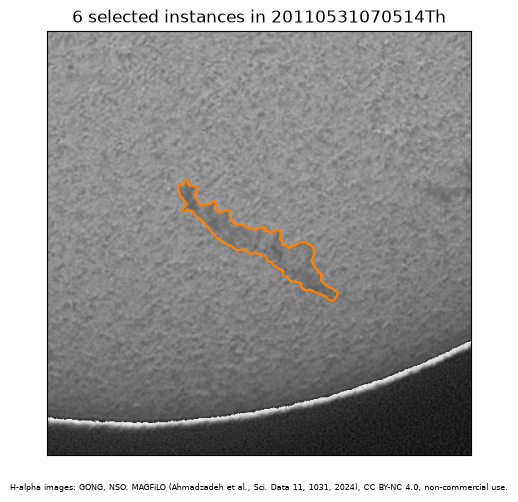

In [7]:
chosen = selection.select(test, test_score, config.TAU)
rows, n_fallback = selection.submission_rows(test, test_score, chosen, test_components)
SUBMISSION = OUT_DIR / "submission.csv"
submission = selection.write_submission(rows, SUBMISSION)
print(f"tau {config.TAU}: {len(chosen)} candidates kept in {len({c[0] for c in chosen})} images, "
      f"{n_fallback} images use the fallback, {len(submission)} rows written to {SUBMISSION.relative_to(ROOT) if SUBMISSION.is_relative_to(ROOT) else SUBMISSION.name}")
print(selection.validate_submission(SUBMISSION, n_images=180))
per_image = submission.filament_id.str.rsplit("_", n=1).str[0].value_counts()
print("instances per test image: mean %.2f, median %d, max %d" % (per_image.mean(), per_image.median(), per_image.max()))

# the selected instances of the example test image
ex_rows = submission[submission.filament_id.str.startswith(EX_STEM + "_")]
from pycocotools import mask as mu
ex_masks = [mu.decode({"size": [2048, 2048], "counts": r.encode("ascii")}).astype(bool) for r in ex_rows.segmentation_rle]
fig = visualize.instances_figure(ex_prob, ex_masks, EX_BOX, ex_img, f"{len(ex_masks)} selected instances in {EX_STEM}"); plt.show()

In [8]:
# compare with the reference submission
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
if REFERENCE.exists():
    ref = pd.read_csv(REFERENCE)
    same_ids = list(ref.filament_id) == list(submission.filament_id)
    n_diff = int((ref.segmentation_rle.values != submission.segmentation_rle.values).sum()) if len(ref) == len(submission) else None
    print("reference rows:", len(ref), "| same ids in the same order:", same_ids, "| rows with a different RLE:", n_diff)
    print("sha256 reference:", sha(REFERENCE))
    print("sha256 this run :", sha(SUBMISSION))
    print("IDENTICAL" if sha(REFERENCE) == sha(SUBMISSION) else "DIFFERENT (expected only if a recompute switch is on)")

reference rows: 1093 | same ids in the same order: True | rows with a different RLE: 0
sha256 reference: 0d277cfceb562591a8562a163bdb026007da084de9d5b77fea3023353adaef29
sha256 this run : 0d277cfceb562591a8562a163bdb026007da084de9d5b77fea3023353adaef29
IDENTICAL


## Stage 7: evaluation on the out-of-fold predictions

The 707 training images were scored by models that never saw them (stages 1, 3, 4 use the published folds; stage 5 uses
cross-fitting by image), so the selection below is an honest estimate of the quality on unseen images.

**Metric.** Panoptic Quality as in the competition: a predicted and an annotated mask are a true positive if
IoU > 0.5; PQ = sum(IoU of the true positives) / (TP + FP/2 + FN/2). Every annotator's masks are scored separately
against the prediction and the counts are pooled over all 1154 (image, annotator) pairs. `SQ` is the mean IoU of the true
positives and `RQ = TP / (TP + FP/2 + FN/2)`. Dice is `2|A and B| / (|A| + |B|)`.

**Relations.** Two definitions of a *partner* are reported. *Overlap*: any pixel overlap (IoU > 0). *Half area*: a
prediction is a fragment of an annotated mask if at least half of its area lies inside it, and an annotated mask is
covered by a prediction if at least half of its area lies inside that prediction. One-to-many: annotated masks with two or
more partners (the filament is split). Many-to-one: predictions with two or more partners (filaments are merged). The overlap rule
counts thin slivers, the half-area rule does not.

out-of-fold PQ from the stored targets at tau 0.30, three cross-fitting shuffles: {0: 0.46461, 1: 0.46502, 2: 0.46592} mean 0.46518
kept candidates per image (seed 0): 6.04


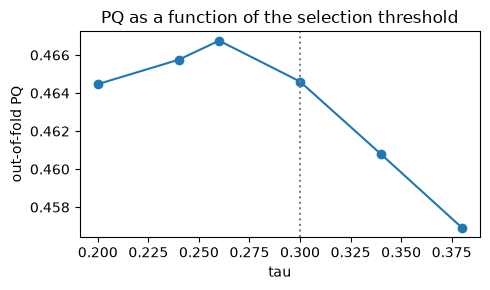

{0.2: 0.4645, 0.24: 0.4658, 0.26: 0.4668, 0.3: 0.4646, 0.34: 0.4608, 0.38: 0.4569}


In [9]:
KEPT = {}
for seed in (0, 1, 2):
    sc = oof_scores[f"score_seed{seed}"].values
    KEPT[seed] = selection.select(train, sc, config.TAU)
fast_pq = {s: evaluation.target_based_pq(train, KEPT[s], N_GT) for s in KEPT}
print("out-of-fold PQ from the stored targets at tau %.2f, three cross-fitting shuffles:" % config.TAU,
      {s: round(v, 5) for s, v in fast_pq.items()}, "mean", round(float(np.mean(list(fast_pq.values()))), 5))
print("kept candidates per image (seed 0): %.2f" % (len(KEPT[0]) / 707))

taus = [0.20, 0.24, 0.26, 0.30, 0.34, 0.38]
curve = {t: evaluation.target_based_pq(train, selection.select(train, oof_scores["score_seed0"].values, t), N_GT) for t in taus}
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(list(curve), list(curve.values()), "o-")
ax.axvline(config.TAU, color="gray", ls=":")
ax.set_xlabel("tau"); ax.set_ylabel("out-of-fold PQ"); ax.set_title("PQ as a function of the selection threshold")
fig.tight_layout(); fig.savefig(OUT_DIR / "pq_vs_tau.png", dpi=150); plt.show()
print({t: round(v, 4) for t, v in curve.items()})

In [10]:
if HAVE_ANNOTATIONS:
    annotations = candidates.load_annotations(TRAIN_JSON)
    sel0 = pd.DataFrame(KEPT[0], columns=KEY)
    stems = sorted(maps["oof_probs_unet"].files)
    result = evaluation.evaluate_selection(sel0, maps["oof_probs_unet"], annotations, stems, log=lambda m: None)
    pq = result["pq"]
    print("exact out-of-fold evaluation (seed 0, tau %.2f): PQ %.4f  SQ %.4f  RQ %.4f   TP %d  FP %d  FN %d" %
          (config.TAU, pq["PQ"], pq["SQ"], pq["RQ"], pq["TP"], pq["FP"], pq["FN"]))
    print("difference to the target-based value:", round(pq["PQ"] - fast_pq[0], 6))
else:
    result = None
    print("competition images or TRAIN_JSON not found: set PQTREE_COMPETITION_DIR and PQTREE_TRAIN_JSON to run the exact evaluation")

exact out-of-fold evaluation (seed 0, tau 0.30): PQ 0.4647  SQ 0.6905  RQ 0.6730   TP 5097  FP 1852  FN 3102
difference to the target-based value: 6.2e-05


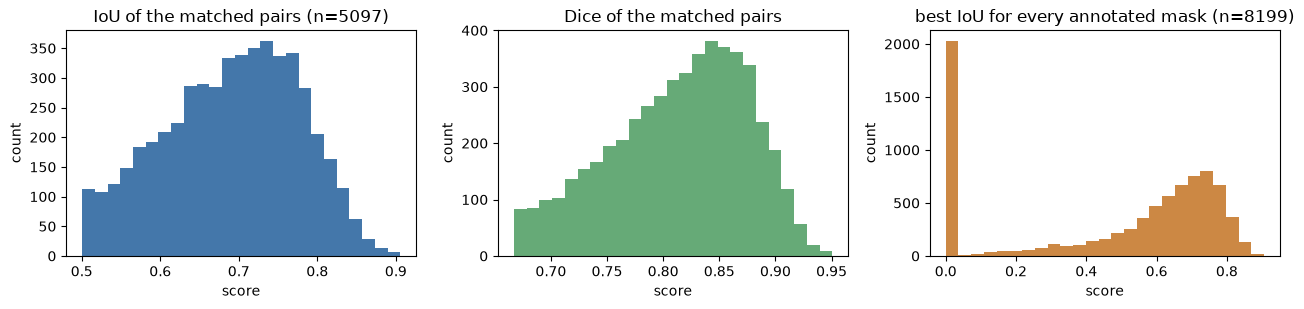

IoU and Dice of the matched pairs (n = 5097):
       mean    10%    25%    50%    75%    90%
IoU   0.690  0.568  0.629  0.698  0.757  0.798
Dice  0.814  0.724  0.772  0.822  0.862  0.888
annotated masks with best IoU > 0.5: 0.622 | best Dice > 0.5: 0.702
           gt_masks  predictions  one_to_one  one_to_many  many_to_one  gt_without_partner  pred_without_partner
overlap        8199         6948        5097          178          144                2025                   730
half_area      8199         6948        5097          165          128                2404                  1420
overlap   one-to-many: 2.2 % of annotated masks | many-to-one: 2.1 % of predictions
half_area one-to-many: 2.0 % of annotated masks | many-to-one: 1.8 % of predictions
annotated masks per (image, annotator) pair: 7.10 | predictions per pair: 6.02


In [11]:
if result is not None:
    gt, pr = result["gt"], result["pred"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    axes[0].hist(result["matched_iou"], bins=25, color="#4477aa"); axes[0].set_title("IoU of the matched pairs (n=%d)" % len(result["matched_iou"]))
    axes[1].hist(result["matched_dice"], bins=25, color="#66aa77"); axes[1].set_title("Dice of the matched pairs")
    axes[2].hist(gt.best_iou, bins=25, color="#cc8844"); axes[2].set_title("best IoU for every annotated mask (n=%d)" % len(gt))
    for a in axes: a.set_xlabel("score"); a.set_ylabel("count")
    fig.tight_layout(); fig.savefig(OUT_DIR / "iou_dice_distributions.png", dpi=150); plt.show()
    print("IoU and Dice of the matched pairs (n = %d):" % len(result["matched_iou"]))
    print(evaluation.quantile_table(result).to_string())
    print("annotated masks with best IoU > 0.5: %.3f | best Dice > 0.5: %.3f" % ((gt.best_iou > 0.5).mean(), (gt.best_dice > 0.5).mean()))
    rel = pd.DataFrame({rule: evaluation.relation_counts(result, rule) for rule in ("overlap", "half_area")}).T
    print(rel.to_string())
    for rule in rel.index:
        print("%-9s one-to-many: %.1f %% of annotated masks | many-to-one: %.1f %% of predictions" %
              (rule, 100 * rel.loc[rule, "one_to_many"] / rel.loc[rule, "gt_masks"], 100 * rel.loc[rule, "many_to_one"] / rel.loc[rule, "predictions"]))
    print("annotated masks per (image, annotator) pair: %.2f | predictions per pair: %.2f" % (len(gt) / 1154, len(pr) / 1154))

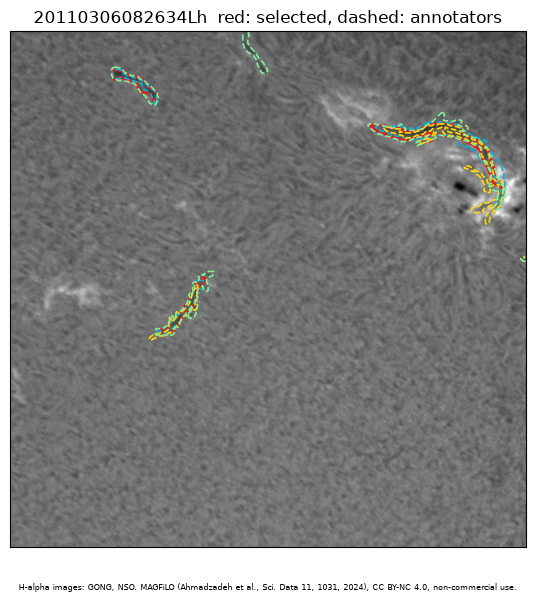

In [12]:
# one training image: selected instances and the outlines of every annotator
if result is not None:
    from pqtree.candidates import label_image
    by_image, ids_of_stem = annotations
    n_sel = sel0.groupby("stem").size()
    pick = [s for s in sorted(n_sel.index) if len(ids_of_stem[s]) >= 2 and n_sel[s] >= 6][0]
    labs = {}
    masks = []
    for r in sel0[sel0.stem == pick].itertuples():
        if r.level not in labs:
            labs[r.level] = label_image(maps["oof_probs_unet"][pick], int(r.level))
        masks.append(labs[r.level] == r.cid)
    def uncrop(g):
        full = np.zeros((2048, 2048), bool); full[g[0]:g[1], g[2]:g[3]] = g[4]; return full
    annot = [[uncrop(g) for g in ann] for ann in candidates.annotator_masks(by_image, ids_of_stem[pick])]
    box = visualize.box_around(np.logical_or.reduce(masks), size=640)
    tr_img = image_reader(TRAIN_IMAGES)(pick)
    fig = visualize.annotator_figure(maps["oof_probs_unet"][pick], masks, annot, box, tr_img, pick); plt.show()

## Summary

| quantity | value |
|---|---|
| file written | `outputs/submission.csv` |
| equal to the reference submission | see the comparison above |
| out-of-fold PQ (pooled, 707 training images) | printed in stage 7 |

Peak memory and run time of this notebook are printed below.

In [13]:
print("run time of this notebook: %.1f min" % ((time.time() - T_START) / 60))
print("peak resident memory: %.2f GB" % (resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 ** 2))

run time of this notebook: 7.0 min
peak resident memory: 0.83 GB
